Dataset downloaded successfully!
                   Open         High          Low        Close    Volume
Date                                                                    
2021-11-18  1135.289551  1148.673096  1130.697632  1141.427490   8505625
2021-11-22  1124.259766  1130.213135  1084.986084  1090.870239  24124307
2021-11-23  1076.702148  1108.176514  1065.603149  1101.069336  25326999
2021-11-24  1098.369629  1112.168457  1081.547974  1085.170776  16820296
2021-11-25  1095.139160  1154.672607  1087.824341  1150.495972  42401936


c:\Users\Aishu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mplfinance\_arg_validators.py:84: UserWarning: 


            POSSIBLE TO SEE DETAILS (Candles, Ohlc-Bars, Etc.)
   For more information see:
   - https://github.com/matplotlib/mplfinance/wiki/Plotting-Too-Much-Data
   
   TO SILENCE THIS WARNING, set `type='line'` in `mpf.plot()`
   OR set kwarg `warn_too_much_data=N` where N is an integer 
   LARGER than the number of data points you want to plot.

  warnings.warn('\n\n ================================================================= '+
findfont: Failed to find font weight semibold, now using 700.


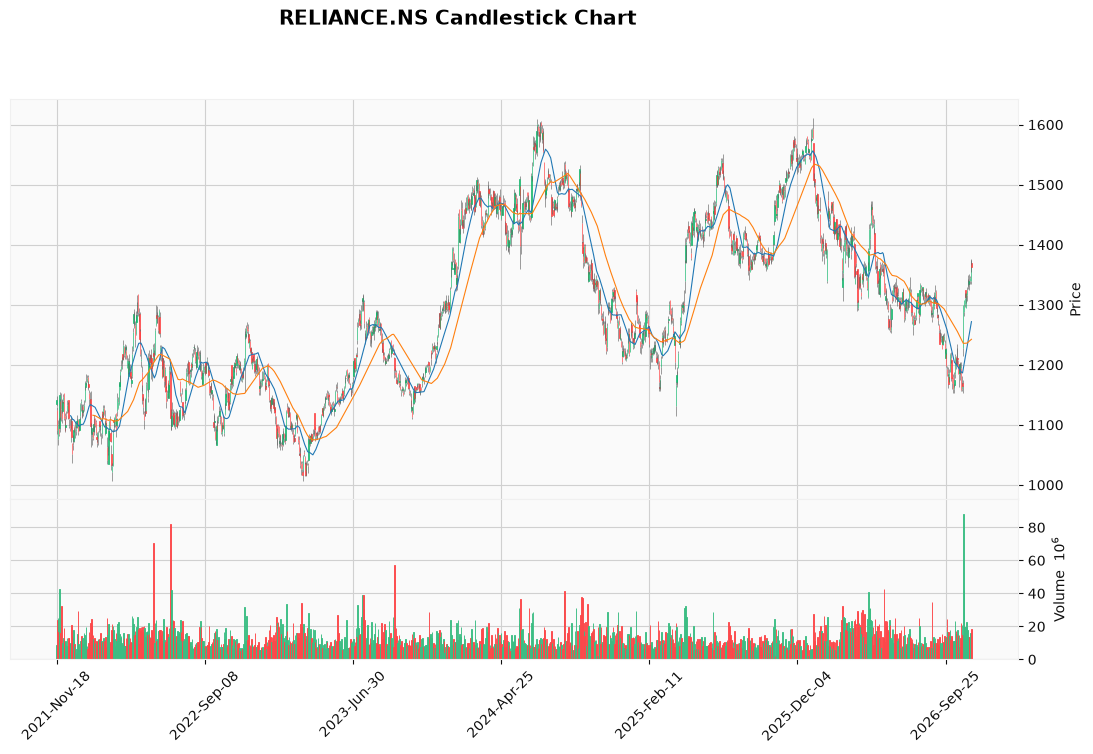

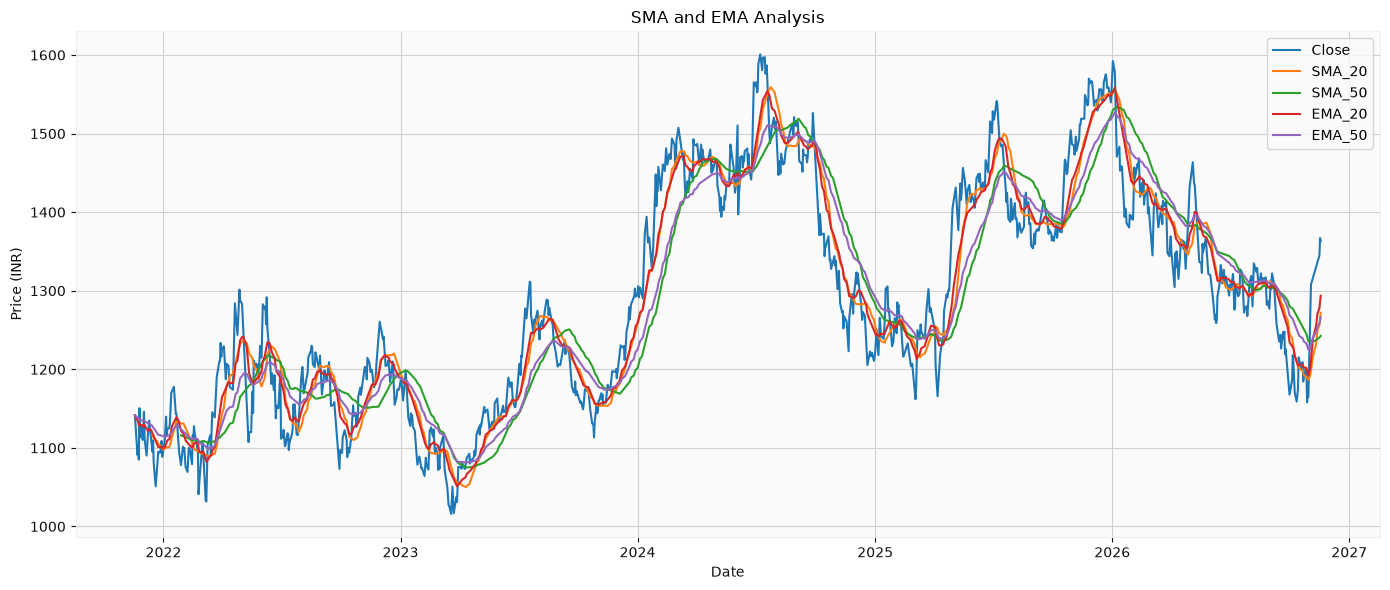

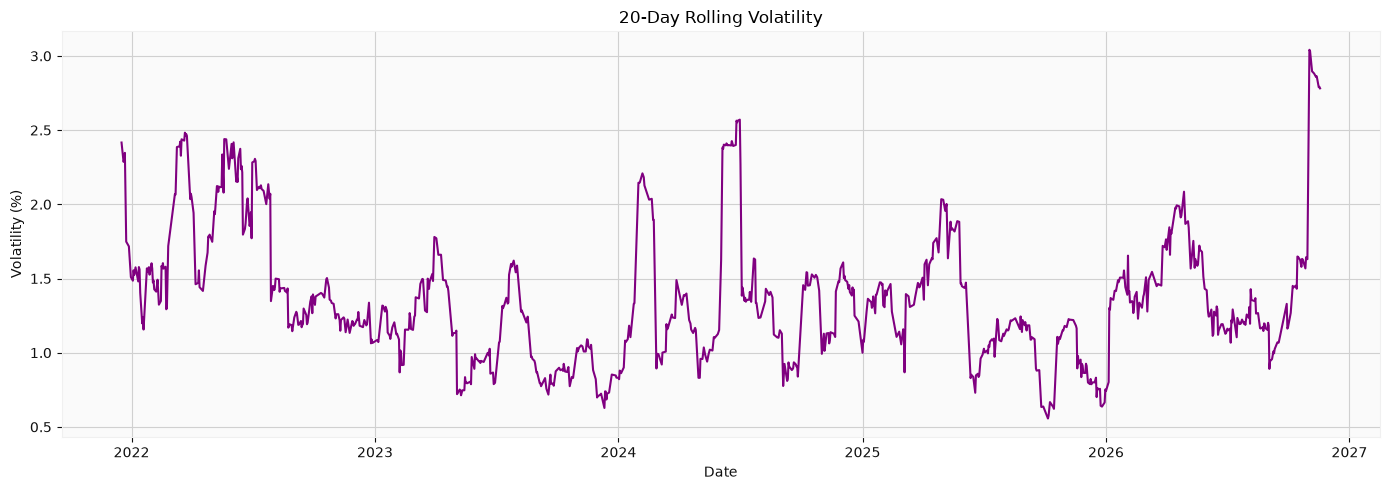

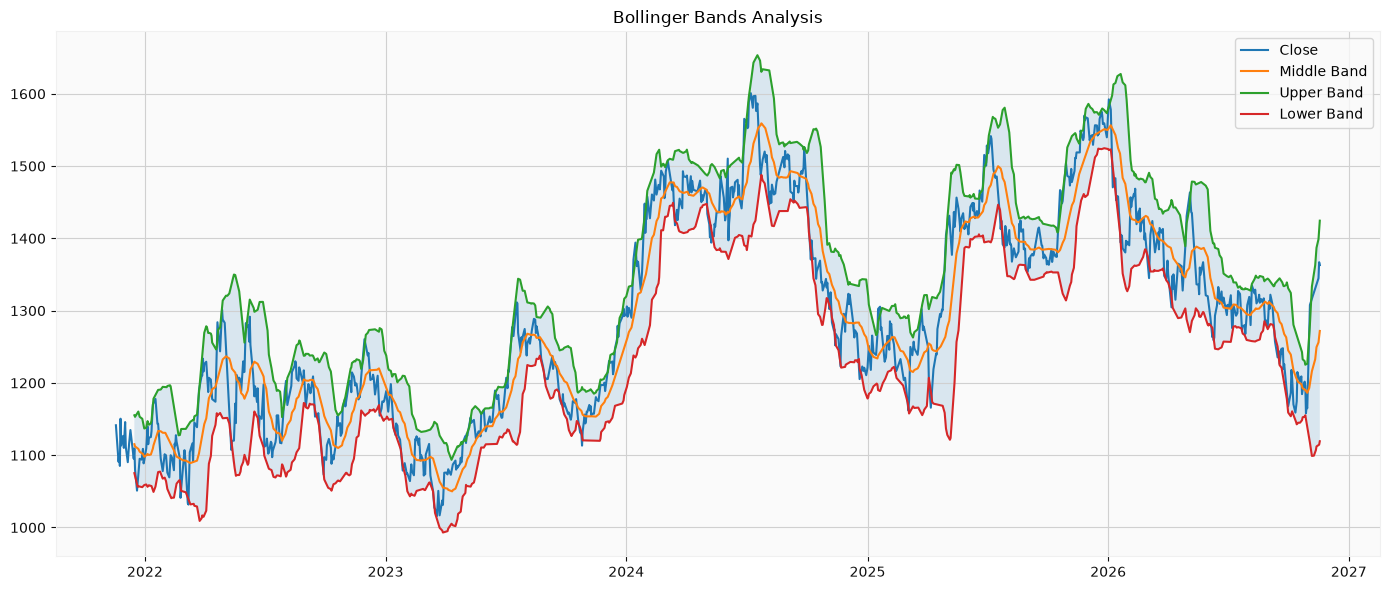

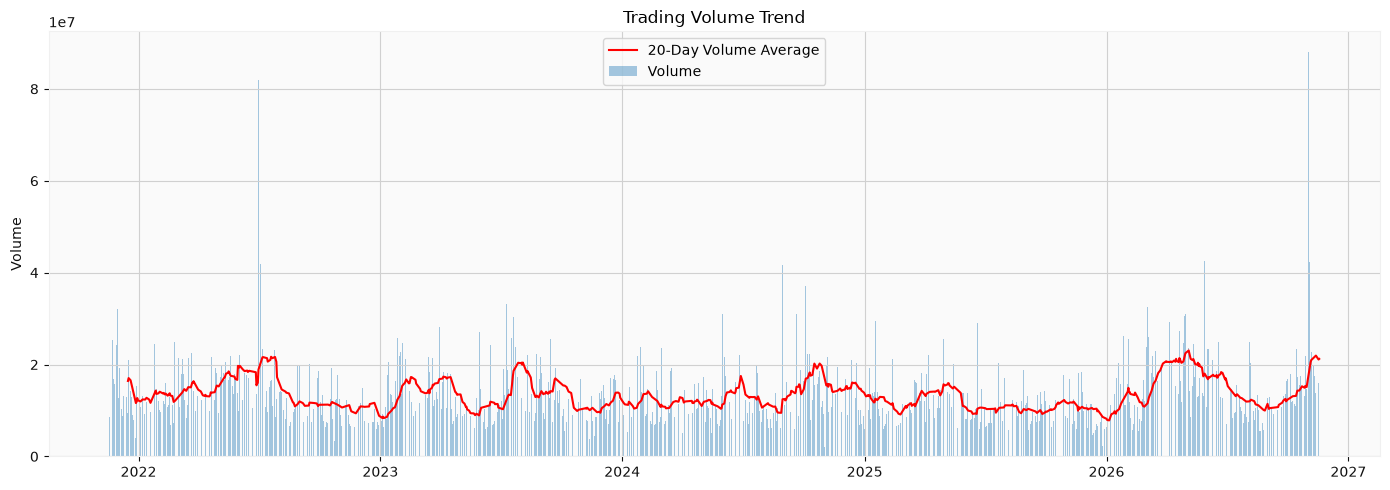

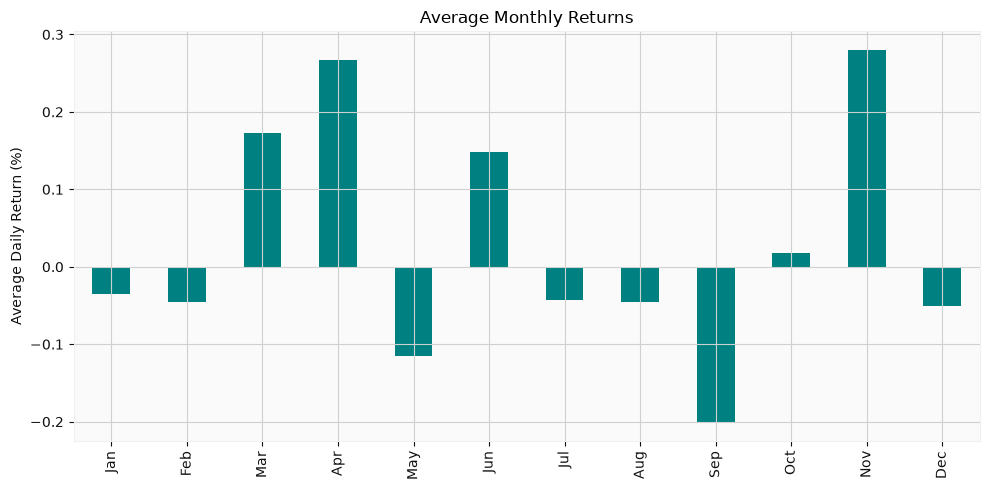

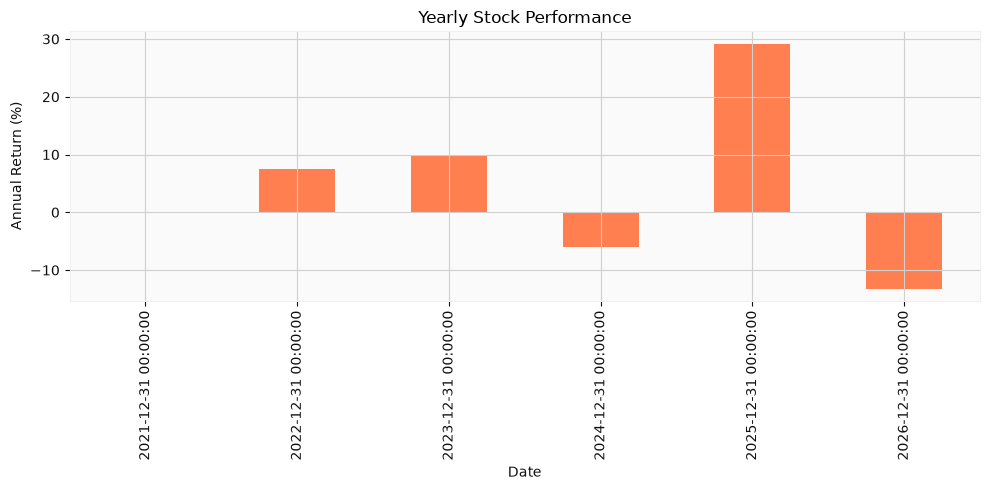

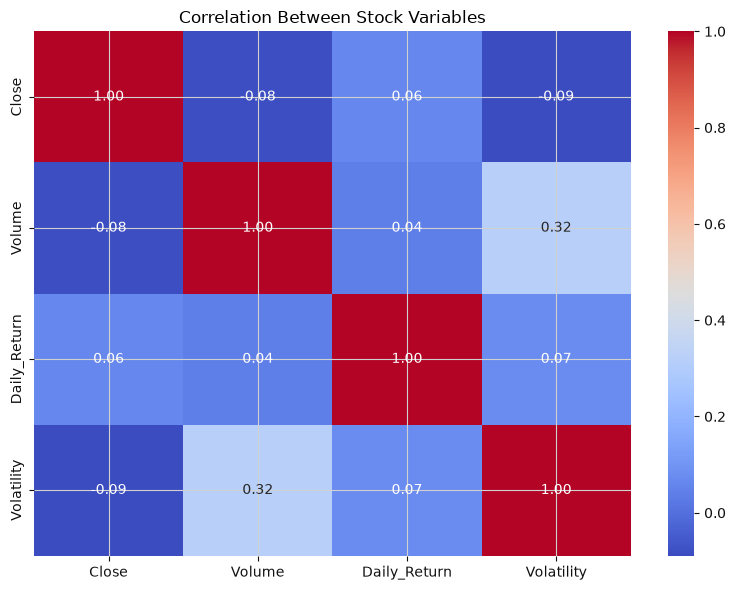


Significant Price Changes (above 3%):
                  Close  Daily_Return    Volume
Date                                           
2025-05-12  1436.500000      0.043058  10674081
2025-07-21  1428.599976     -0.032114  22442744
2025-10-20  1466.800049      0.035291  24721978
2026-01-06  1507.599976     -0.044674  27417125
2026-01-19  1413.599976     -0.030386  20392765
2026-02-03  1437.099976      0.033587  25456171
2026-03-05  1389.400024      0.033011  25957532
2026-03-27  1348.099976     -0.045998  23266517
2026-04-06  1304.699951     -0.033913  29274881
2026-04-08  1347.800049      0.033114  21817543
2026-05-11  1388.199951     -0.032748  15261787
2026-08-06  1325.000000      0.035156  20342297
2026-10-15  1215.000000      0.034395  23456219
2026-10-28  1158.000000     -0.031934  21866598
2026-11-02  1300.000000      0.115976  88121121

========== TREND ANALYSIS ==========
Short-term trend: Bullish
Price position: Above SMA 50
EMA trend: Positive
Volatility: High

========== SUM

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mplfinance as mpf
import seaborn as sns

sns.set_style("whitegrid")

ticker = "RELIANCE.NS"

data = yf.download(
    ticker,
    period="5y",
    interval="1d",
    auto_adjust=False,
    multi_level_index=False,
    progress=False
)

if data.empty:
    raise ValueError("No data downloaded. Check ticker or internet connection.")

if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

cols = ["Open", "High", "Low", "Close", "Volume"]
data = data[cols].apply(pd.to_numeric, errors="coerce")
data = data.dropna().sort_index()

data.to_csv("stock_data.csv")

print("Dataset downloaded successfully!")
print(data.head())

data["SMA_20"] = data["Close"].rolling(20).mean()
data["SMA_50"] = data["Close"].rolling(50).mean()

data["EMA_20"] = data["Close"].ewm(
    span=20, adjust=False
).mean()

data["EMA_50"] = data["Close"].ewm(
    span=50, adjust=False
).mean()

data["Daily_Return"] = data["Close"].pct_change()

data["Volatility"] = (
    data["Daily_Return"].rolling(20).std()
)

data["BB_Middle"] = data["Close"].rolling(20).mean()
std = data["Close"].rolling(20).std()

data["Upper_Band"] = data["BB_Middle"] + 2 * std
data["Lower_Band"] = data["BB_Middle"] - 2 * std

data["Volume_SMA"] = data["Volume"].rolling(20).mean()

mpf.plot(
    data[cols].dropna(),
    type="candle",
    volume=True,
    mav=(20, 50),
    style="yahoo",
    title=f"{ticker} Candlestick Chart",
    figsize=(14, 8)
)

plt.figure(figsize=(14, 6))

for column in ["Close", "SMA_20", "SMA_50", "EMA_20", "EMA_50"]:
    plt.plot(data.index, data[column], label=column)

plt.title("SMA and EMA Analysis")
plt.xlabel("Date")
plt.ylabel("Price (INR)")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.plot(data.index, data["Volatility"] * 100, color="purple")
plt.title("20-Day Rolling Volatility")
plt.ylabel("Volatility (%)")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

plt.plot(data.index, data["Close"], label="Close")
plt.plot(data.index, data["BB_Middle"], label="Middle Band")
plt.plot(data.index, data["Upper_Band"], label="Upper Band")
plt.plot(data.index, data["Lower_Band"], label="Lower Band")

plt.fill_between(
    data.index,
    data["Upper_Band"],
    data["Lower_Band"],
    alpha=0.15
)

plt.title("Bollinger Bands Analysis")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))

plt.bar(data.index, data["Volume"], alpha=0.4, label="Volume")
plt.plot(data.index, data["Volume_SMA"], color="red",
         label="20-Day Volume Average")

plt.title("Trading Volume Trend")
plt.ylabel("Volume")
plt.legend()
plt.tight_layout()
plt.show()

monthly = data["Daily_Return"].groupby(
    data.index.month
).mean() * 100

monthly.index = [
    pd.Timestamp(2000, month, 1).strftime("%b")
    for month in monthly.index
]

monthly.plot(kind="bar", figsize=(10, 5), color="teal")
plt.title("Average Monthly Returns")
plt.ylabel("Average Daily Return (%)")
plt.tight_layout()
plt.show()

yearly = data["Close"].resample("YE").last().pct_change() * 100

yearly.plot(kind="bar", figsize=(10, 5), color="coral")
plt.title("Yearly Stock Performance")
plt.ylabel("Annual Return (%)")
plt.tight_layout()
plt.show()

corr = data[
    ["Close", "Volume", "Daily_Return", "Volatility"]
].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Stock Variables")
plt.tight_layout()
plt.show()

significant = data[
    data["Daily_Return"].abs() > 0.03
]

print("\nSignificant Price Changes (above 3%):")
print(significant[["Close", "Daily_Return", "Volume"]].tail(15))

latest = data.iloc[-1]

print("\n========== TREND ANALYSIS ==========")

print("Short-term trend:",
      "Bullish" if latest["SMA_20"] > latest["SMA_50"]
      else "Bearish")

print("Price position:",
      "Above SMA 50" if latest["Close"] > latest["SMA_50"]
      else "Below SMA 50")

print("EMA trend:",
      "Positive" if latest["EMA_20"] > latest["EMA_50"]
      else "Negative")

print("Volatility:",
      "High" if latest["Volatility"] > data["Volatility"].mean()
      else "Low")

print("\n========== SUMMARY REPORT ==========")
print("Stock:", ticker)
print("Trading Days:", len(data))
print("Highest Price:", round(data["Close"].max(), 2))
print("Lowest Price:", round(data["Close"].min(), 2))
print("Average Price:", round(data["Close"].mean(), 2))
print("Average Daily Return (%):",
      round(data["Daily_Return"].mean() * 100, 4))
print("Average Volatility (%):",
      round(data["Volatility"].mean() * 100, 4))
print("Average Volume:", round(data["Volume"].mean(), 0))

data.to_csv("reliance_complete_analysis.csv")

print("\nAnalysis completed successfully!")
print("Files saved:")
print("1. stock_data.csv")
print("2. reliance_complete_analysis.csv")
